# Global Health Progress, 2000–2019: A Data Story from the World Bank's Health, Nutrition and Population Statistics

**3520872** | CSCU9M3 — Scripting for Data Science | Autumn 2026

In [1]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Colab always has a module called google.colab loaded automatically, so I
# can use that to check if the notebook is running in Colab or not, and
# point at the right folder for the data either way.
running_in_colab = "google.colab" in sys.modules

if running_in_colab:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_DIR = "/content/drive/MyDrive/Colab Notebooks/Untitled folder/data/hnp_stats"
else:
    DATA_DIR = "data/hnp_stats"

Mounted at /content/drive


## Executive Summary

_[Written last, after the findings below are known — max 200 words.]_

## Introduction

_[Written last, after the findings below are known — max 200 words.]_

## Data Cleaning

The World Bank's Health, Nutrition and Population Statistics (HNP) data comes as several linked CSV files: a main data file (one row per country/indicator, one column per year 1960–2021), a country metadata file, and an indicator metadata file. The main file needs cleaning before any analysis. It mixes real countries with regional and income-group aggregates in the same rows, it contains hundreds of indicators and six decades of years that this report does not use, and many country/indicator combinations have no data at all for the years we care about.

In [3]:
data = pd.read_csv(f"{DATA_DIR}/HNP_StatsData.csv")
country_info = pd.read_csv(f"{DATA_DIR}/HNP_StatsCountry.csv")

# Both files end every line with a trailing comma, so pandas reads an extra
# empty column called "Unnamed: xx" at the end. I get rid of those columns
# before doing anything else with the data.
extra_columns = [col for col in data.columns if col.startswith("Unnamed")]
data = data.drop(columns=extra_columns)

extra_columns = [col for col in country_info.columns if col.startswith("Unnamed")]
country_info = country_info.drop(columns=extra_columns)

print("Main data file:", data.shape)
print("Country info file:", country_info.shape)

Main data file: (117838, 66)
Country info file: (265, 30)


Removing non-country aggregates. Rows such as "Africa Eastern and Southern" or "High income" are regional/income-group aggregates, not countries, and would distort any country-level comparison (e.g. a regional aggregate being counted alongside the countries that make it up). An alternative would be to hand-pick a list of aggregate names to drop, but this was rejected because it is brittle and error-prone, it relies on recognising every aggregate by hand and would silently miss any that are mis-spelled or renamed. The country metadata file already distinguishes real countries from aggregates, every real country has a Region value, while every aggregate has a blank one. Filtering on that column is a rule based on the data rather than a manual list.

In [4]:
# Rows with no Region are not real countries, they are totals for a whole
# region or income group (e.g. "Africa Eastern and Southern"), so I filter
# those out here and keep just the columns I need from the country info.
real_countries = country_info[country_info["Region"].notna()]
real_countries = real_countries[["Country Code", "Region", "Income Group"]]

data = data.merge(real_countries, on="Country Code", how="inner")

print("Rows after removing region/income totals:", len(data))
print("Number of countries left:", data["Country Code"].nunique())

Rows after removing region/income totals: 96131
Number of countries left: 217


Choosing indicators. The full dataset covers hundreds of indicators spanning population, nutrition, disease, and health systems, far more than a 1500-word report can cover. Five indicators were chosen to address one question (has global health improved since 2000, and is that improvement shared equally?), life expectancy at birth, under-5 mortality, measles immunisation coverage, fertility rate, and current health expenditure (% of GDP). These were chosen for good data coverage (checked below), and because together they cover outcomes (mortality, life expectancy), a driver (health spending), and context (fertility, immunisation).

In [5]:
indicators_wanted = {
    "SP.DYN.LE00.IN": "Life expectancy at birth (years)",
    "SH.DYN.MORT": "Under-5 mortality (per 1,000 live births)",
    "SH.IMM.MEAS": "Measles immunisation (% of children 12-23 months)",
    "SP.DYN.TFRT.IN": "Fertility rate (births per woman)",
    "SH.XPD.CHEX.GD.ZS": "Current health expenditure (% of GDP)",
}

data = data[data["Indicator Code"].isin(indicators_wanted)]
data["Indicator Name"] = data["Indicator Code"].map(indicators_wanted)
print("Rows after keeping only the 5 indicators I want:", len(data))

Rows after keeping only the 5 indicators I want: 1085


Choosing the year range. Current health expenditure (% of GDP) is only reported from 2000 onwards (an earlier, broader methodology didn't track it), so 2000 is the start of the comparison across all five indicators, using an earlier start would mean comparing on four indicators for most of the window and five only at the end. 2019 is used as the end point rather than the most recent years (2020-2021) because COVID-19 caused sharp, temporary disruption to both health outcomes and data collection in those years, including them would make a "has health improved" comparison partly about the pandemic rather than the longer-run trend this report is about.

In [6]:
YEARS = [str(year) for year in range(2000, 2020)]
columns_to_keep = ["Country Name", "Country Code", "Region", "Income Group",
                    "Indicator Name", "Indicator Code"] + YEARS
data = data[columns_to_keep]
print("Columns kept:", list(data.columns))

Columns kept: ['Country Name', 'Country Code', 'Region', 'Income Group', 'Indicator Name', 'Indicator Code', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019']


Handling missing values. For the before/after comparisons used later in this report, a country/indicator row is only usable if it has a value in both endpoint years, 2000 and 2019. Rows missing either endpoint are dropped rather than filled in by interpolation, interpolating would invent a trend for a country that never reported that indicator reliably, and that gap in reporting is a real feature of the data rather than something to paper over.

In [7]:
missing_2000 = data["2000"].isna().sum()
missing_2019 = data["2019"].isna().sum()
print("Rows missing a 2000 value:", missing_2000)
print("Rows missing a 2019 value:", missing_2019)

clean_data = data.dropna(subset=["2000", "2019"])
clean_data = clean_data.reset_index(drop=True)

percent_kept = round(len(clean_data) / len(data) * 100)
print("Rows kept:", len(clean_data), "out of", len(data), f"({percent_kept}%)")

Rows missing a 2000 value: 117
Rows missing a 2019 value: 114
Rows kept: 961 out of 1085 (89%)


In [8]:
clean_data[["Country Name", "Region", "Income Group", "Indicator Name", "2000", "2019"]].head()

,Country Name,Region,Income Group,Indicator Name,2000,2019
0,Afghanistan,South Asia,Low income,Fertility rate (births per woman),7.485,4.321
1,Afghanistan,South Asia,Low income,Measles immunisation (% of children 12-23 months),27.000,64.000
2,Afghanistan,South Asia,Low income,Life expectancy at birth (years),55.841,64.833
3,Afghanistan,South Asia,Low income,"Under-5 mortality (per 1,000 live births)",129.200,60.100
4,Albania,Europe & Central Asia,Upper middle income,Fertility rate (births per woman),2.157,1.597


clean_data is the dataset used for the rest of this report: real countries only, five indicators, years 2000–2019, with both endpoint years guaranteed present for every row. Intermediate years (2001–2018) may still contain gaps for some countries, this is fine because only the Exploratory Data Analysis section uses them, as year-by-year averages rather than individual country values.

## Exploratory Data Analysis

This section looks at what clean_data actually contains before the descriptive analytics questions. Three things are worth checking first, how much of each indicator is missing, how the 217 countries split across regions, and what the spread of a typical indicator looks like across countries.

Indicator Name
Current health expenditure (% of GDP)                17.1
Fertility rate (births per woman)                     8.3
Life expectancy at birth (years)                      8.3
Measles immunisation (% of children 12-23 months)    12.4
Under-5 mortality (per 1,000 live births)            11.1
dtype: float64


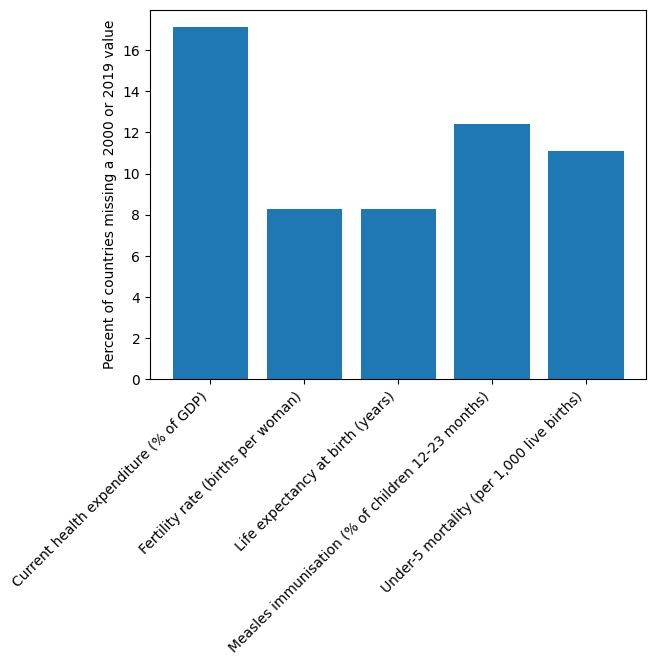

In [9]:
# I check missingness on data (the 1085 rows before I dropped the ones
# missing an endpoint year), grouped by indicator, so I can see if the
# missing values are spread evenly or concentrated in one indicator.
rows_missing_an_endpoint = data[data["2000"].isna() | data["2019"].isna()]
missing_by_indicator = rows_missing_an_endpoint.groupby("Indicator Name").size()
total_by_indicator = data.groupby("Indicator Name").size()

missing_percent = (missing_by_indicator / total_by_indicator * 100).round(1)
print(missing_percent)

plt.bar(missing_percent.index, missing_percent.values)
plt.ylabel("Percent of countries missing a 2000 or 2019 value")
plt.xticks(rotation=45, ha="right")
plt.show()

Checking missing data by indicator. Current health expenditure is missing for 37 of 217 countries, close to double the missing rate of life expectancy and fertility rate, which are each missing only 18. This is because health expenditure is a newer indicator with less historical reporting behind it, so any result that uses it rests on a smaller set of countries than the other four indicators.

Region
North America                  3
South Asia                     8
Middle East & North Africa    21
East Asia & Pacific           35
Latin America & Caribbean     37
Sub-Saharan Africa            48
Europe & Central Asia         56
Name: Country Code, dtype: int64


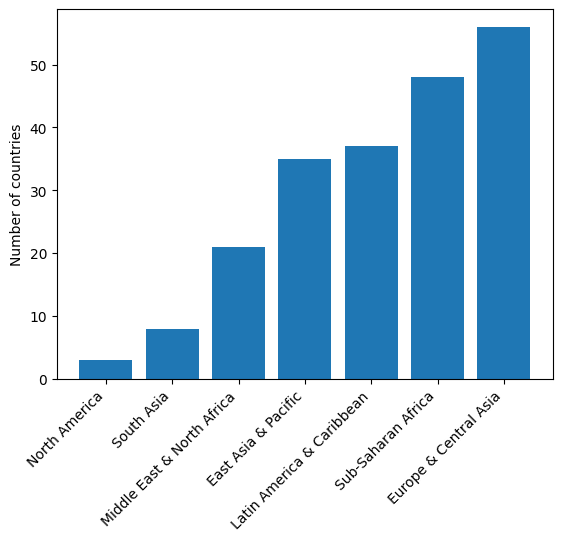

In [10]:
countries_per_region = clean_data.groupby("Region")["Country Code"].nunique()
countries_per_region = countries_per_region.sort_values()
print(countries_per_region)

plt.bar(countries_per_region.index, countries_per_region.values)
plt.ylabel("Number of countries")
plt.xticks(rotation=45, ha="right")
plt.show()

Checking country counts by region. The regions are far from equal in size, North America has 3 countries and South Asia has 8, while Europe & Central Asia has 56. This means a difference between two small regions could come from just one or two countries moving, so regional comparisons later in this report lean more on the larger regions.

Life expectancy, mean: 73.0 median: 74.2
Fertility rate, mean: 2.62 median: 2.19


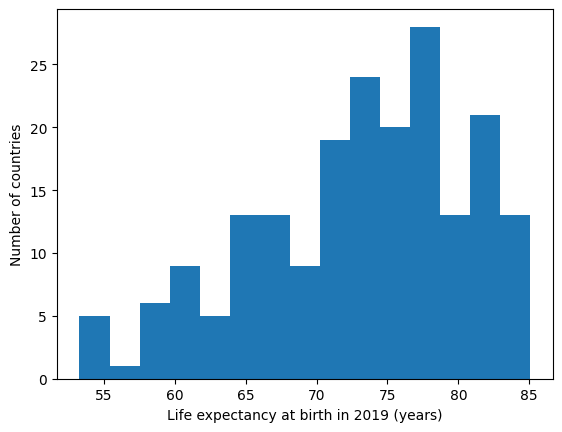

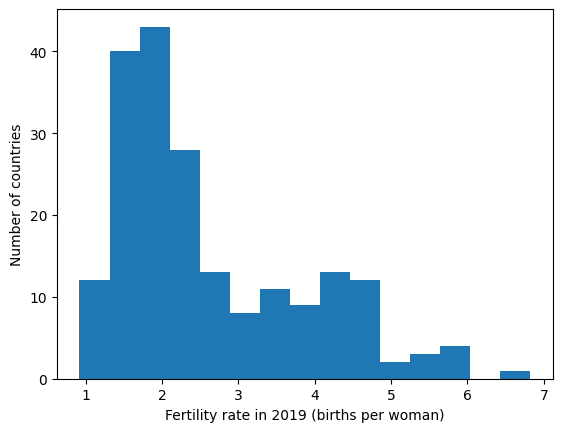

In [11]:
life_expectancy_2019 = clean_data[clean_data["Indicator Name"] == "Life expectancy at birth (years)"]["2019"]
fertility_2019 = clean_data[clean_data["Indicator Name"] == "Fertility rate (births per woman)"]["2019"]

print("Life expectancy, mean:", round(life_expectancy_2019.mean(), 1), "median:", round(life_expectancy_2019.median(), 1))
print("Fertility rate, mean:", round(fertility_2019.mean(), 2), "median:", round(fertility_2019.median(), 2))

plt.hist(life_expectancy_2019, bins=15)
plt.xlabel("Life expectancy at birth in 2019 (years)")
plt.ylabel("Number of countries")
plt.show()

plt.hist(fertility_2019, bins=15)
plt.xlabel("Fertility rate in 2019 (births per woman)")
plt.ylabel("Number of countries")
plt.show()

Checking the shape of two indicators. Life expectancy in 2019 has a mean of 73.0 years against a median of 74.2, so the mean sits below the median, a smaller group of countries with much lower life expectancy pulls it down. Fertility rate shows the opposite pattern, a mean of 2.62 births per woman against a median of 2.19, so a smaller group of high fertility countries pulls the mean up instead. This means the median is the more representative figure for a typical country on both indicators, and the descriptive analytics section below uses that where it matters.

## Descriptive Analytics

This section answers three questions using clean_data. Two of them compare a 2000 value against a 2019 value within a group, Income Group for the first question and Region for the third, so I wrote one function, average_by_group, and used it twice rather than writing the same groupby code out twice.

In [12]:
def average_by_group(indicator_name, group_column):
    # Takes the rows for one indicator, groups them by whichever column I
    # pass in (Income Group or Region), and works out the average 2000
    # value, the average 2019 value, and how much it changed.
    subset = clean_data[clean_data["Indicator Name"] == indicator_name]
    grouped = subset.groupby(group_column)[["2000", "2019"]].mean()
    grouped["change"] = grouped["2019"] - grouped["2000"]
    return grouped.round(1)

### Has under-5 mortality fallen equally across income groups?

Child mortality under the age of 5 is one of the clearest signs of whether a health system is working, so whether poorer countries are catching up to richer ones on this measure, or falling further behind, says something real about where progress is actually happening.

                      2000  2019  change
Income Group                            
Low income           149.0  69.8   -79.2
Lower middle income   77.7  37.9   -39.9
Upper middle income   34.9  18.4   -16.6
High income           10.3   6.1    -4.1

percent change:
Income Group
Low income            -53.0
Lower middle income   -51.0
Upper middle income   -48.0
High income           -40.0
dtype: float64


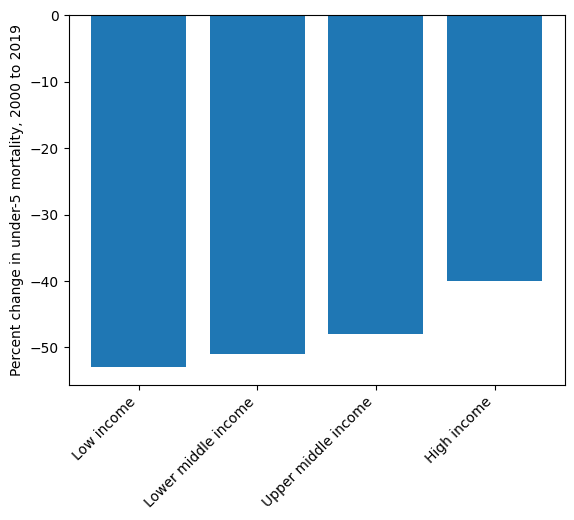

In [13]:
mortality_by_income = average_by_group("Under-5 mortality (per 1,000 live births)", "Income Group")
mortality_by_income = mortality_by_income.sort_values("2000", ascending=False)
print(mortality_by_income)

# The change column on its own makes low income countries look like they
# did most of the improving, but that is partly just because they started
# so much higher. Dividing by the 2000 value puts all four groups on the
# same scale, as a percent change instead of a raw one.
percent_change = (mortality_by_income["change"] / mortality_by_income["2000"] * 100).round(0)
print("\npercent change:")
print(percent_change)

plt.bar(percent_change.index, percent_change.values)
plt.ylabel("Percent change in under-5 mortality, 2000 to 2019")
plt.xticks(rotation=45, ha="right")
plt.show()

Low income countries cut under-5 mortality from 149.0 to 69.8 per 1,000 births, a 53% drop, the largest percent drop of the four groups, even though they started with by far the highest rate. High income countries cut theirs from 10.3 to 6.1, a 40% drop, the smallest. All four groups land in a fairly narrow band, between 40% and 53%, so the poorest countries have not been improving more slowly than richer ones on this measure, if anything slightly faster.

### Is health spending related to how long people live?

This is the kind of question that matters for where health budgets go. If the relationship between spending and life expectancy is weak, raising spending on its own is unlikely to move life expectancy much, and the answer points to other factors instead.

Countries with both values: 171
Correlation: 0.44


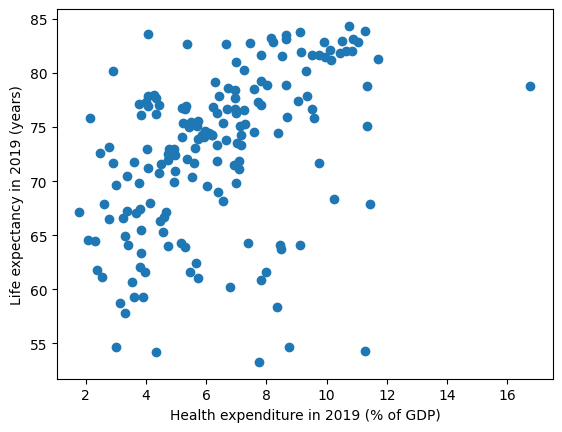

In [14]:
life_expectancy = clean_data[clean_data["Indicator Name"] == "Life expectancy at birth (years)"]
life_expectancy = life_expectancy[["Country Code", "2019"]].rename(columns={"2019": "life_expectancy"})

health_spending = clean_data[clean_data["Indicator Name"] == "Current health expenditure (% of GDP)"]
health_spending = health_spending[["Country Code", "2019"]].rename(columns={"2019": "health_spending"})

# I only use 2019 here instead of the whole 2000 to 2019 window, because
# health expenditure only starts in 2000. This keeps the comparison to
# countries with a real value in the most recent year, rather than mixing
# different years together.
both = life_expectancy.merge(health_spending, on="Country Code", how="inner")
print("Countries with both values:", len(both))

correlation = both["life_expectancy"].corr(both["health_spending"])
print("Correlation:", round(correlation, 2))

plt.scatter(both["health_spending"], both["life_expectancy"])
plt.xlabel("Health expenditure in 2019 (% of GDP)")
plt.ylabel("Life expectancy in 2019 (years)")
plt.show()

Across the 171 countries with both figures for 2019, health expenditure and life expectancy have a correlation of 0.44. This is a moderate positive relationship, not a strong one, countries that spend more of their GDP on health do tend to have longer life expectancy on average, but spending only explains part of the difference between countries. Other things, such as income and the kind of care that money buys, are likely doing the rest of the work.

### Which regions improved measles immunisation the most, and which fell behind?

Measles immunisation coverage is a basic marker of how far routine childhood healthcare reaches, so a region moving backwards on it is a different kind of problem to a region that is simply slower to catch up.

                            2000  2019  change
Region                                        
North America               93.5  90.0    -3.5
Latin America & Caribbean   90.8  90.1    -0.7
Middle East & North Africa  88.1  90.1     2.0
Europe & Central Asia       91.1  94.0     2.8
East Asia & Pacific         81.7  89.8     8.1
Sub-Saharan Africa          61.6  77.6    16.0
South Asia                  70.1  90.5    20.4


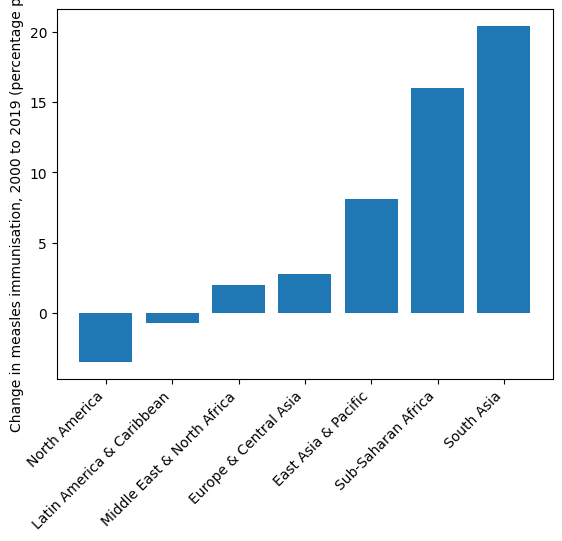

In [15]:
immunisation_by_region = average_by_group("Measles immunisation (% of children 12-23 months)", "Region")
immunisation_by_region = immunisation_by_region.sort_values("change")
print(immunisation_by_region)

plt.bar(immunisation_by_region.index, immunisation_by_region["change"])
plt.ylabel("Change in measles immunisation, 2000 to 2019 (percentage points)")
plt.xticks(rotation=45, ha="right")
plt.show()

South Asia gained the most, up 20.4 percentage points from 70.1% to 90.5%, and Sub-Saharan Africa gained 16.0 points. North America is the only region that fell, from 93.5% to 90.0%, and Latin America & Caribbean slipped slightly too, from 90.8% to 90.1%. The regions that started closest to full coverage are the ones that lost ground, while the regions that started furthest behind caught up the most. A region already above 90% has little room left to grow, so a small dip there points to coverage slipping rather than to running out of room to improve.

## Suggestions

_[Phase 4 — to be completed next.]_

## Bibliography

_[Phase 6 — to be completed last.]_